# 04 · Predicting fish weight (regression)

**Question:** how well do water-quality readings and time predict fish weight in a pond the model has not seen?

**Evaluation:** cross-validation grouped by pond (`GroupKFold`), so every test fold contains ponds the model never saw. A random row split would put readings from the same pond and day in both train and test and inflate the scores.

**Features:** daily mean temperature, dissolved oxygen, pH, nitrate, population and days since the pond's first record. Fish length is excluded: it is measured with weight on the same day and maps almost one-to-one to it, so it would leak the answer.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import importlib
import src.pond_pipeline
importlib.reload(src.pond_pipeline)  # pick up edits to src/ even if this kernel imported it earlier
from src.pond_pipeline import *  # noqa: F401,F403  (column names, thresholds, helpers)

# Raw pond CSVs live in data/raw/ (see data/README.md). Override with POND_RAW_DIR if needed.
RAW = Path(os.environ.get("POND_RAW_DIR", RAW_DIR))
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

pond_day = pd.read_csv(PROCESSED_DIR / "pond_day.csv", parse_dates=["date"])
FEATURES = MODEL_SENSOR_COLS + [POPULATION, "days_since_start"]
X, y, groups = pond_day[FEATURES], pond_day[WEIGHT], pond_day["pond_id"]
cv = GroupKFold(n_splits=min(5, groups.nunique()))
print(X.shape, "ponds:", groups.nunique())

(856, 6) ponds: 11


### Which processed data is used

Shows the file this notebook reads, when notebook 03 wrote it, and which version of the cleaning made it. If it warns, restart notebook 03's kernel and run it again.

In [3]:
check_processed(PROCESSED_DIR / "pond_day.csv")

file:     C:\Users\99451\OneDrivee\Desktop\pond_dataset\data\processed\pond_day.csv
written:  2026-11-25 14:04:38
made by:  2026-11-25.4 (dates per column, stale weights, pond 11 restock, DO 0.01-20)
src code: 2026-11-25.4 (dates per column, stale weights, pond 11 restock, DO 0.01-20)  (C:\Users\99451\OneDrivee\Desktop\pond_dataset\src\pond_pipeline.py)


,rows,first,last,max_weight
pond_id,,,,
1,81,2021-06-19,2021-10-13,318.640000
2,111,2021-06-19,2021-10-31,394.660000
3,76,2021-06-19,2021-10-12,294.920000
4,68,2021-06-19,2021-09-05,223.730000
6,89,2021-06-19,2021-10-13,304.760000
7,127,2021-06-18,2021-12-30,1026.457143
8,56,2021-06-18,2021-12-06,841.200000
9,101,2021-06-18,2021-10-13,431.200000
10,18,2021-06-25,2021-12-05,689.142900


## Why fish length is not a feature

Each recorded length goes with essentially one weight, so a model given length can look the weight up. In the first version of this analysis that produced R² ≈ 0.99998, which reflected this lookup, not the effect of water quality.

In [4]:
rows = pd.read_csv(PROCESSED_DIR / "pond_clean.csv", usecols=["pond_id", LENGTH, WEIGHT]).dropna()
per_length = rows.groupby(["pond_id", LENGTH])[WEIGHT].nunique()
print(f"{(per_length == 1).mean():.1%} of (pond, length) pairs map to a single weight")

99.9% of (pond, length) pairs map to a single weight


## Models

Two baselines frame the results: predicting the mean weight, and a linear model on time alone. The sensor models are only useful to the extent they beat the time-only baseline.

In [5]:
models = {
    "Baseline: mean": (DummyRegressor(), FEATURES),
    "Baseline: days only (linear)": (LinearRegression(), ["days_since_start"]),
    "Linear regression": (make_pipeline(StandardScaler(), LinearRegression()), FEATURES),
    "Lasso (alpha=0.1)": (make_pipeline(StandardScaler(), Lasso(alpha=0.1, random_state=RANDOM_STATE)), FEATURES),
    "Decision tree (depth 5)": (DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE), FEATURES),
    "Random forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1), FEATURES),
    "XGBoost": (XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, random_state=RANDOM_STATE), FEATURES),
}

results, predictions = [], {}
for name, (model, cols) in models.items():
    pred = cross_val_predict(model, X[cols], y, groups=groups, cv=cv)
    predictions[name] = pred
    results.append({"model": name,
                    "R2": r2_score(y, pred),
                    "RMSE (g)": np.sqrt(mean_squared_error(y, pred)),
                    "MAE (g)": mean_absolute_error(y, pred)})
results = pd.DataFrame(results).set_index("model").sort_values("RMSE (g)")
results.to_csv(RESULTS_DIR / "regression_results.csv")
results

,R2,RMSE (g),MAE (g)
model,,,
Baseline: days only (linear),0.889764,81.801988,59.872106
XGBoost,0.879017,85.697036,48.753755
Lasso (alpha=0.1),0.862756,91.274366,62.362603
Linear regression,0.861920,91.552213,62.583644
Random forest,0.810263,107.319474,48.898989
Decision tree (depth 5),0.805530,108.649828,53.714633
Baseline: mean,-0.198519,269.727523,215.610531


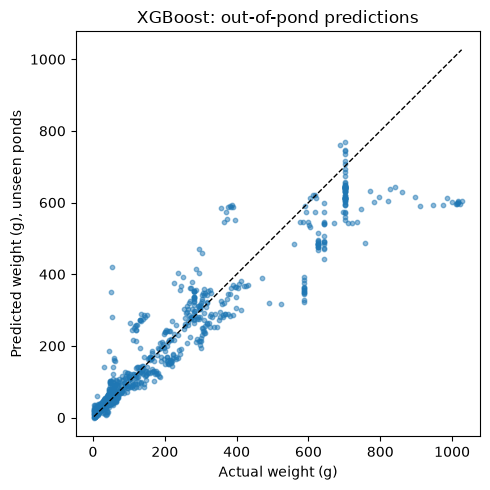

In [6]:
best = results.drop(index=[i for i in results.index if i.startswith("Baseline")]).index[0]
plt.figure(figsize=(5, 5))
plt.scatter(y, predictions[best], s=10, alpha=0.5)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("Actual weight (g)")
plt.ylabel("Predicted weight (g), unseen ponds")
plt.title(f"{best}: out-of-pond predictions")
plt.tight_layout()
plt.show()

## Feature importance (random forest, fitted on all ponds)

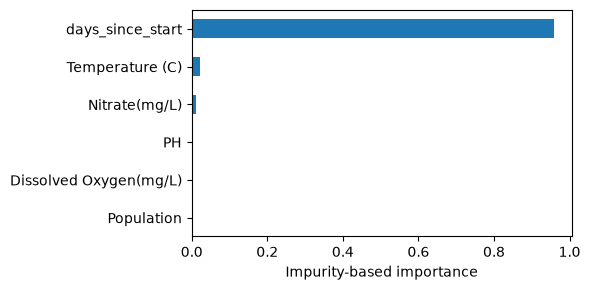

In [7]:
rf = models["Random forest"][0].fit(X, y)
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(6, 3))
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()

**Reading the results:** compare each model with the *days only* baseline. Growth over time explains most of the weight; the gap between that baseline and the sensor models is what water quality adds. Ponds differ in species, stocking date and feeding, which grouped cross-validation exposes and a random split would hide.